# Chart2Data Intelligence — Étape 1 : Exploration des données (ChartQA)

**Objectif** : explorer ChartQA avant de construire le pipeline (image → table → réponse).

Contenu du notebook :
1. Chargement et vue d'ensemble
2. Valeurs manquantes et doublons
3. Questions : longueur, mots fréquents, types
4. Images : dimensions et formats
5. Tables sous-jacentes : taille et contenu
6. Types de graphiques et sources (estimation)
7. Vérification multimodale image ↔ question ↔ table
8. Synthèse et limites

> ⚠️ Adapte `ROOT` à l'endroit où tu as dézippé ChartQA. Le notebook détecte automatiquement les fichiers, mais vérifie la structure affichée en section 1.

In [1]:
import os, json, glob, re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = True
pd.set_option("display.max_colwidth", 100)

## 1. Chargement et vue d'ensemble

In [2]:
# >>> À ADAPTER : dossier contenant train/ val/ test/
ROOT = "ChartQA Dataset"

# Affiche la structure pour vérifier
for split in ["train", "val", "test"]:
    p = os.path.join(ROOT, split)
    print(split, "->", sorted(os.listdir(p)) if os.path.isdir(p) else "INTROUVABLE")

train -> ['png', 'tables', 'train_augmented.json', 'train_human.json']
val -> ['png', 'tables', 'val_augmented.json', 'val_human.json']
test -> ['png', 'tables', 'test_augmented.json', 'test_human.json']


In [3]:
def load_split(split):
    """Charge les questions humaines (H) et générées (M) d'un split."""
    dfs = []
    for src, tag in [("human", "human"), ("augmented", "augmented")]:
        path = os.path.join(ROOT, split, f"{split}_{src}.json")
        if os.path.exists(path):
            with open(path, encoding="utf-8") as f:
                d = pd.DataFrame(json.load(f))
            d["source"] = tag
            d["split"] = split
            dfs.append(d)
        else:
            print("Fichier absent :", path)
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

qa = pd.concat([load_split(s) for s in ["train", "val", "test"]], ignore_index=True)
qa["label"] = qa["label"].astype(str)
print("Colonnes :", list(qa.columns))
qa.head()

Colonnes : ['imgname', 'query', 'label', 'source', 'split']


,imgname,query,label,source,split
0,10095.png,Is the value of Favorable 38 in 2015?,Yes,human,train
1,10095.png,How many values are below 40 in Unfavorable graph?,6,human,train
2,10149.png,In which year the value was 51?,2014,human,train
3,10149.png,What is the sum favourable value in the year 2014 and 2015?,95,human,train
4,10154.png,In which year the Mexican governments campaign against drugs traffickers is making 47 percent pr...,2012,human,train


In [4]:
summary = (qa.groupby(["split", "source"])
             .agg(n_questions=("query", "size"), n_images=("imgname", "nunique"))
             .reset_index())
print(summary.to_string(index=False))
print("\nTotal questions :", len(qa), "| Total images uniques :", qa["imgname"].nunique())

split    source  n_questions  n_images
 test augmented         1250       987
 test     human         1250       625
train augmented        20901     15474
train     human         7398      3699
  val augmented          960       680
  val     human          960       480

Total questions : 32719 | Total images uniques : 20882


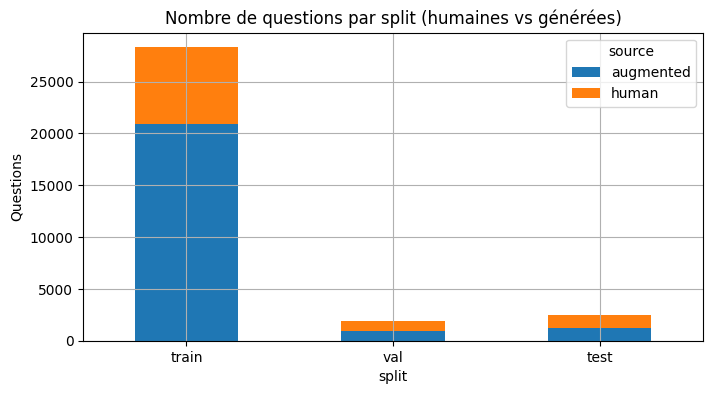

In [5]:
# Visualisation 1 : répartition des questions par split et par origine
pivot = qa.groupby(["split", "source"]).size().unstack(fill_value=0).reindex(["train", "val", "test"])
pivot.plot(kind="bar", stacked=True)
plt.title("Nombre de questions par split (humaines vs générées)")
plt.ylabel("Questions"); plt.xticks(rotation=0); plt.show()

## 2. Valeurs manquantes et doublons

In [6]:
print("Valeurs manquantes par colonne :")
print(qa.isna().sum(), "\n")
print("Réponses vides :", (qa["label"].str.strip() == "").sum())

dup_exact = qa.duplicated(subset=["imgname", "query", "label"]).sum()
dup_qimg = qa.duplicated(subset=["imgname", "query"]).sum()
print("Doublons exacts (image, question, réponse) :", dup_exact)
print("Même image + même question (réponses éventuellement différentes) :", dup_qimg)

# Questions identiques posées sur plusieurs images (normal, mais utile à connaître)
top_q = qa["query"].str.lower().value_counts().head(10)
print("\nQuestions les plus répétées :")
print(top_q)

# Chevauchement d'images entre splits (risque de fuite de données)
imgs = {s: set(qa.loc[qa.split == s, "imgname"]) for s in ["train", "val", "test"]}
print("\nImages communes train/test :", len(imgs["train"] & imgs["test"]))
print("Images communes train/val  :", len(imgs["train"] & imgs["val"]))

Valeurs manquantes par colonne :
imgname    0
query      0
label      0
source     0
split      0
dtype: int64 

Réponses vides : 0
Doublons exacts (image, question, réponse) : 179
Même image + même question (réponses éventuellement différentes) : 253

Questions les plus répétées :
query
what was the average ticket price in the 2005/06 season?                          16
who was the most valuable player at the 2018 fifa world cup?                      15
what is the difference between the highest and the lowest dark blue bar?          15
how many bars are there in the graph?                                             15
what is the value of the highest dark blue bar?                                   13
what's the value of largest bar?                                                  13
which country is represented by blue color line?                                  12
what is the value of smallest bar?                                                12
the shortest light blue bar min

## 3. Analyse des questions

             count  mean  std  min   25%   50%   75%   max
source                                                    
augmented  23111.0  11.9  3.1  4.0  10.0  12.0  14.0  30.0
human       9608.0  11.0  4.2  3.0   8.0  10.0  13.0  47.0


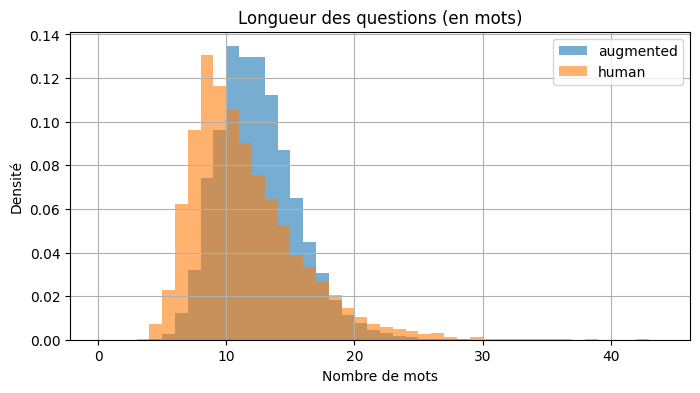

In [7]:
qa["q_len"] = qa["query"].str.split().str.len()
print(qa.groupby("source")["q_len"].describe().round(1))

# Visualisation 2 : longueur des questions (humaines vs générées)
fig, ax = plt.subplots()
for src, g in qa.groupby("source"):
    ax.hist(g["q_len"], bins=range(0, 45), alpha=.6, label=src, density=True)
ax.set_title("Longueur des questions (en mots)")
ax.set_xlabel("Nombre de mots"); ax.set_ylabel("Densité"); ax.legend()
plt.show()

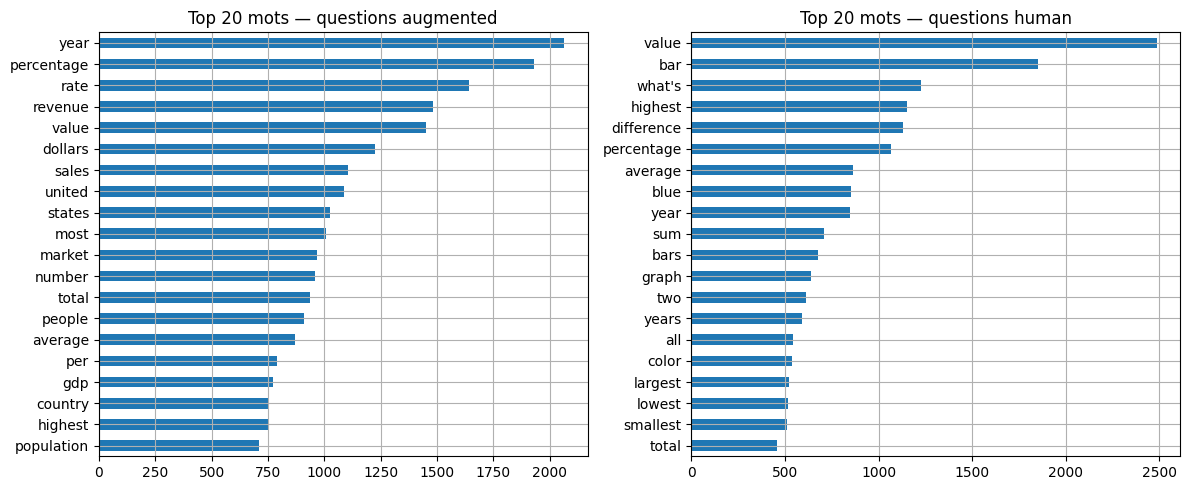

In [8]:
STOP = set("the of in a an and to is was for on what are were that this with by as at from which than "
           "between more less each does did do be it its has have had how many much".split())

def top_words(series, k=20):
    c = Counter()
    for q in series.str.lower():
        c.update(w for w in re.findall(r"[a-z']+", q) if w not in STOP and len(w) > 2)
    return pd.Series(dict(c.most_common(k)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (src, g) in zip(axes, qa.groupby("source")):
    top_words(g["query"]).sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Top 20 mots — questions {src}")
plt.tight_layout(); plt.show()

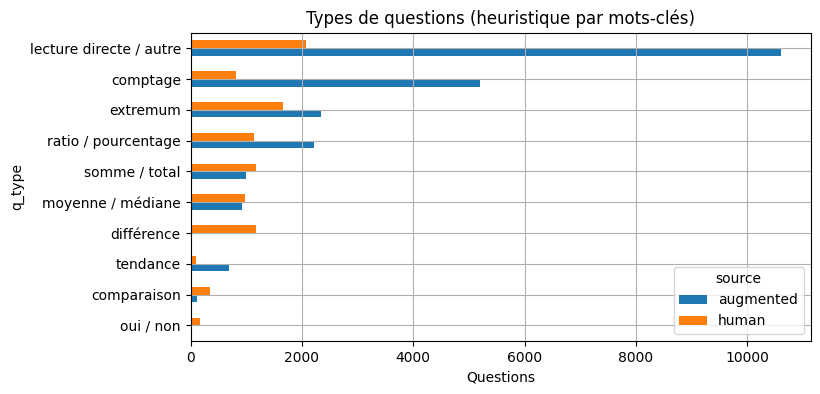

In [9]:
# Types de questions (estimation par mots-clés, à raffiner)
def question_type(q):
    q = q.lower()
    if re.search(r"\b(difference|differ|gap)\b", q): return "différence"
    if re.search(r"\b(sum|total|combined|add)\b", q): return "somme / total"
    if re.search(r"\b(average|mean|median)\b", q): return "moyenne / médiane"
    if re.search(r"\b(ratio|percentage|percent|proportion)\b", q): return "ratio / pourcentage"
    if re.search(r"\b(highest|lowest|largest|smallest|maximum|minimum|most|least|peak)\b", q): return "extremum"
    if re.search(r"\b(greater|less|higher|lower|larger|smaller|more than|than)\b", q): return "comparaison"
    if re.search(r"\b(trend|increase|decrease|grow|decline|over time|change)\b", q): return "tendance"
    if re.search(r"\b(how many|count|number of)\b", q): return "comptage"
    if re.match(r"^(is|are|was|were|does|do|did|can)\b", q): return "oui / non"
    return "lecture directe / autre"

qa["q_type"] = qa["query"].apply(question_type)
ct = pd.crosstab(qa["q_type"], qa["source"])
ct.loc[ct.sum(axis=1).sort_values().index].plot(kind="barh")
plt.title("Types de questions (heuristique par mots-clés)"); plt.xlabel("Questions"); plt.show()

In [10]:
# Types de réponses : numériques vs textuelles
def is_num(s):
    try:
        float(str(s).replace(",", "").replace("%", "").replace("$", "").strip()); return True
    except ValueError:
        return False

qa["ans_numeric"] = qa["label"].apply(is_num)
print(qa.groupby("source")["ans_numeric"].mean().round(3).rename("part de réponses numériques"))
print("\nExemples de réponses non numériques :")
print(qa.loc[~qa.ans_numeric, "label"].value_counts().head(10))

source
augmented    0.849
human        0.685
Name: part de réponses numériques, dtype: float64

Exemples de réponses non numériques :
label
Yes              417
No               336
China            133
Germany           96
Brazil            61
France            58
gray              49
United States     43
Blue              38
Red               35
Name: count, dtype: int64


## 4. Analyse des images

In [11]:
def find_png_dir(split):
    for name in ["png", "images", "img"]:
        d = os.path.join(ROOT, split, name)
        if os.path.isdir(d): return d
    return None

PNG_DIR = {s: find_png_dir(s) for s in ["train", "val", "test"]}
print(PNG_DIR)

rng = np.random.default_rng(42)
rows = []
for split, d in PNG_DIR.items():
    if d is None: continue
    files = sorted(glob.glob(os.path.join(d, "*")))
    sample = rng.choice(files, size=min(1500, len(files)), replace=False)
    for p in sample:
        try:
            with Image.open(p) as im:
                rows.append(dict(split=split, file=os.path.basename(p), w=im.width, h=im.height,
                                 mode=im.mode, fmt=im.format))
        except Exception as e:
            rows.append(dict(split=split, file=os.path.basename(p), w=None, h=None, mode="ERREUR", fmt=str(e)))

img_df = pd.DataFrame(rows)
img_df["ratio"] = img_df["w"] / img_df["h"]
print("Images échantillonnées :", len(img_df))
print(img_df[["w", "h", "ratio"]].describe().round(2))
print("\nFormats / modes :")
print(img_df.groupby(["fmt", "mode"]).size())

{'train': 'ChartQA Dataset\\train\\png', 'val': 'ChartQA Dataset\\val\\png', 'test': 'ChartQA Dataset\\test\\png'}
Images échantillonnées : 4056
             w        h    ratio
count  4056.00  4056.00  4056.00
mean    778.42   594.71     1.35
std     111.54   153.74     0.23
min     184.00   273.00     0.33
25%     800.00   557.00     1.42
50%     800.00   557.00     1.44
75%     800.00   557.00     1.44
max    1242.00  1856.00     2.04

Formats / modes :
fmt  mode
PNG  RGB      376
     RGBA    3680
dtype: int64


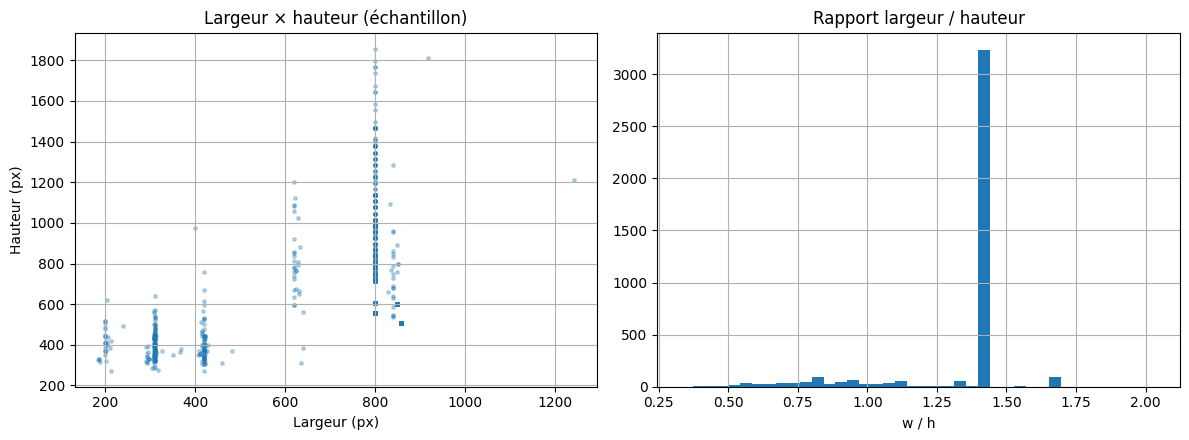

In [12]:
# Visualisation 3 : dimensions des images
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(img_df["w"], img_df["h"], s=6, alpha=.3)
axes[0].set_title("Largeur × hauteur (échantillon)"); axes[0].set_xlabel("Largeur (px)"); axes[0].set_ylabel("Hauteur (px)")
axes[1].hist(img_df["ratio"].dropna(), bins=40)
axes[1].set_title("Rapport largeur / hauteur"); axes[1].set_xlabel("w / h")
plt.tight_layout(); plt.show()

## 5. Tables sous-jacentes (ground truth)

In [13]:
def table_path(split, imgname):
    base = os.path.splitext(imgname)[0]
    return os.path.join(ROOT, split, "tables", base + ".csv")

def read_table(path):
    try:
        return pd.read_csv(path)
    except Exception:
        return None

# Couverture : combien d'images ont une table ?
cover = []
for split in ["train", "val", "test"]:
    names = qa.loc[qa.split == split, "imgname"].unique()
    has = sum(os.path.exists(table_path(split, n)) for n in names)
    cover.append((split, len(names), has))
print(pd.DataFrame(cover, columns=["split", "images", "avec_table"]))

   split  images  avec_table
0  train   18317       18317
1    val    1056        1056
2   test    1509        1509


        n_rows   n_cols  n_numeric_cols  n_missing
count  1500.00  1500.00         1500.00    1500.00
mean     11.73     2.47            1.40       0.11
std       8.21     1.20            1.23       1.06
min       1.00     2.00            0.00       0.00
25%       6.00     2.00            1.00       0.00
50%      10.00     2.00            1.00       0.00
75%      15.00     2.00            2.00       0.00
max      49.00    14.00           12.00      28.00

Tables avec valeurs manquantes : 42 / 1500


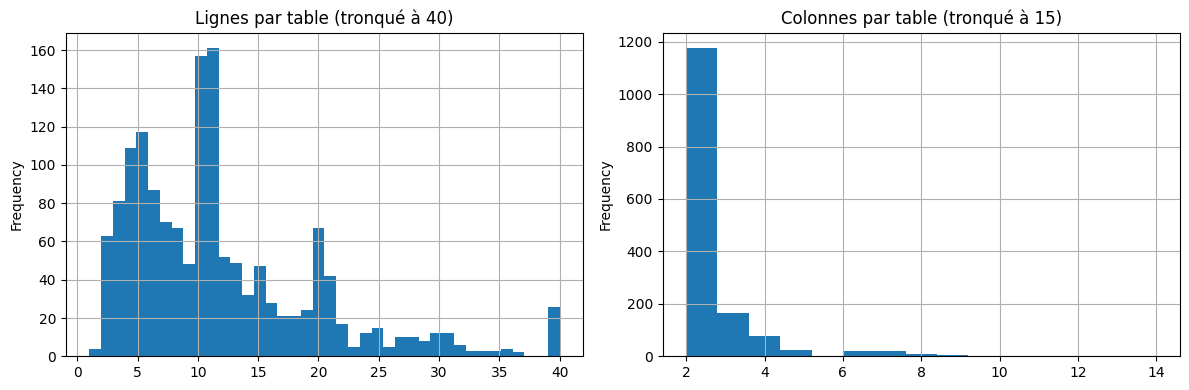

In [14]:
t_rows = []
names = qa.loc[qa.split == "train", "imgname"].unique()
for n in rng.choice(names, size=min(1500, len(names)), replace=False):
    t = read_table(table_path("train", n))
    if t is None: continue
    num_cols = t.select_dtypes(include=np.number).shape[1]
    t_rows.append(dict(imgname=n, n_rows=t.shape[0], n_cols=t.shape[1], n_numeric_cols=num_cols,
                       n_missing=int(t.isna().sum().sum())))
tdf = pd.DataFrame(t_rows)
print(tdf.describe().round(2))
print("\nTables avec valeurs manquantes :", (tdf["n_missing"] > 0).sum(), "/", len(tdf))

# Visualisation 4 : taille des tables
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tdf["n_rows"].clip(upper=40).plot(kind="hist", bins=40, ax=axes[0]); axes[0].set_title("Lignes par table (tronqué à 40)")
tdf["n_cols"].clip(upper=15).plot(kind="hist", bins=15, ax=axes[1]); axes[1].set_title("Colonnes par table (tronqué à 15)")
plt.tight_layout(); plt.show()

## 6. Types de graphiques et sources (estimation)

ChartQA ne fournit pas directement une étiquette « bar / line / pie » dans les fichiers de questions.
On l'estime ici de deux façons (à valider visuellement) :
- à partir des **annotations** (dossier `annotations/`) si elles sont présentes ;
- à défaut, à partir du **préfixe du nom de fichier** pour la **source** (Statista, Pew, OWID, OECD), qui sert de proxy de diversité visuelle.

In [15]:
def infer_source(imgname):
    n = imgname.lower()
    if n.startswith("pew") or "pew" in n: return "Pew"
    if "owid" in n: return "OWID"
    if "oecd" in n: return "OECD"
    if re.match(r"^(\d+|two_col|multi_col)", n): return "Statista (probable)"
    return "autre / inconnu"

img_names = qa.drop_duplicates("imgname")[["split", "imgname"]].copy()
img_names["source_site"] = img_names["imgname"].apply(infer_source)
print(img_names["source_site"].value_counts())

source_site
Statista (probable)    20651
OECD                     231
Name: count, dtype: int64


In [16]:
# Tentative : type de graphique via les annotations (si dossier présent)
def chart_type_from_annotation(split, imgname):
    base = os.path.splitext(imgname)[0]
    for ext in [".json"]:
        p = os.path.join(ROOT, split, "annotations", base + ext)
        if os.path.exists(p):
            try:
                a = json.load(open(p, encoding="utf-8"))
            except Exception:
                return None
            # Clés possibles : à inspecter si None
            for k in ["type", "chart_type", "chartType"]:
                if isinstance(a, dict) and k in a: return str(a[k])
            if isinstance(a, dict):
                keys = set(a.keys())
                if "bars" in keys or "bar" in keys: return "bar"
                if "lines" in keys or "line" in keys: return "line"
                if "pie" in keys or "slices" in keys: return "pie"
    return None

sample_imgs = img_names[img_names.split == "train"].sample(min(1000, (img_names.split == "train").sum()), random_state=0)
sample_imgs["chart_type"] = [chart_type_from_annotation(s, n) for s, n in zip(sample_imgs.split, sample_imgs.imgname)]
print("Annotations exploitables :", sample_imgs["chart_type"].notna().sum(), "/", len(sample_imgs))

if sample_imgs["chart_type"].notna().any():
    sample_imgs["chart_type"].value_counts().plot(kind="bar")
    plt.title("Types de graphiques (échantillon, via annotations)"); plt.xticks(rotation=0); plt.show()
else:
    print("Aucun type trouvé : ouvre un fichier annotations/*.json pour voir sa structure, ou étiquette un échantillon manuellement.")

Annotations exploitables : 0 / 1000
Aucun type trouvé : ouvre un fichier annotations/*.json pour voir sa structure, ou étiquette un échantillon manuellement.


## 7. Vérification multimodale : image ↔ question ↔ réponse ↔ table

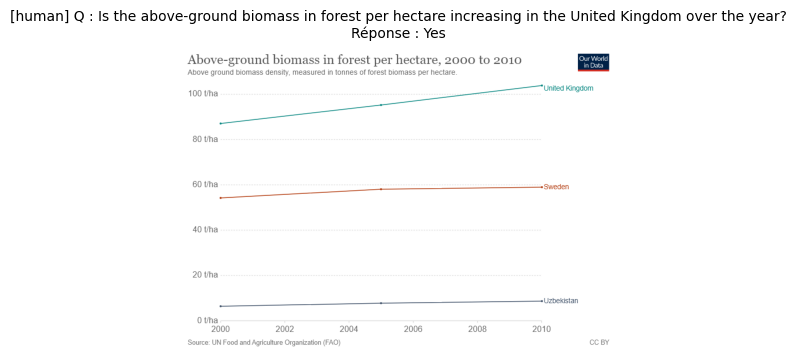

Table associée :


,Entity,2000,2002,2004,2006,2008,2010
0,United Kingdom,87.00,NaN,NaN,NaN,NaN,103.96
1,Sweden,54.15,NaN,NaN,NaN,NaN,58.91
2,Uzbekistan,6.46,NaN,NaN,NaN,NaN,8.72


--------------------------------------------------------------------------------


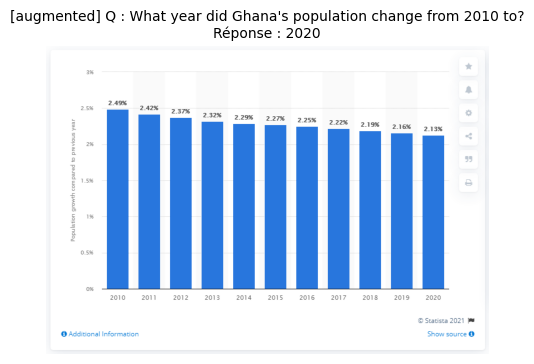

Table associée :


,Characteristic,Population growth compared to previous year
0,2020,2.13%
1,2019,2.16%
2,2018,2.19%
3,2017,2.22%
4,2016,2.25%
5,2015,2.27%
6,2014,2.29%
7,2013,2.32%


--------------------------------------------------------------------------------


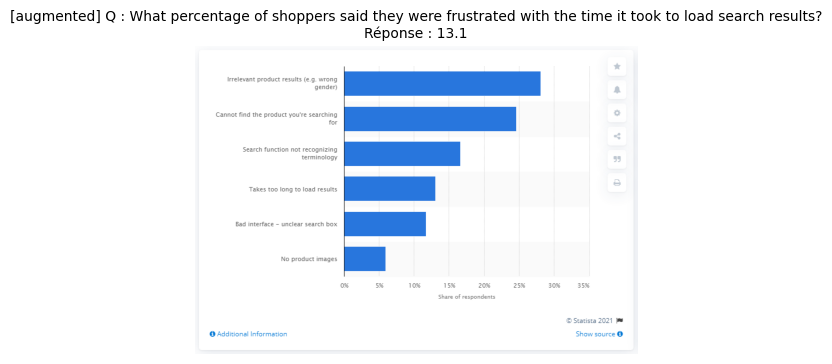

Table associée :


,Characteristic,Share of respondents
0,Irrelevant product results (e.g. wrong gender),28.1%
1,Cannot find the product you're searching for,24.6%
2,Search function not recognizing terminology,16.6%
3,Takes too long to load results,13.1%
4,Bad interface - unclear search box,11.7%
5,No product images,5.9%


--------------------------------------------------------------------------------


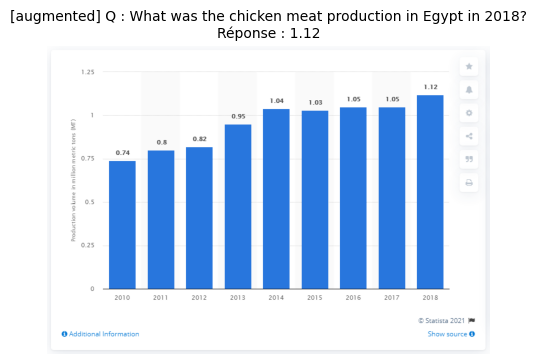

Table associée :


,Characteristic,Production volume in million metric tons (MT)
0,2018,1.12
1,2017,1.05
2,2016,1.05
3,2015,1.03
4,2014,1.04
5,2013,0.95
6,2012,0.82
7,2011,0.80


--------------------------------------------------------------------------------


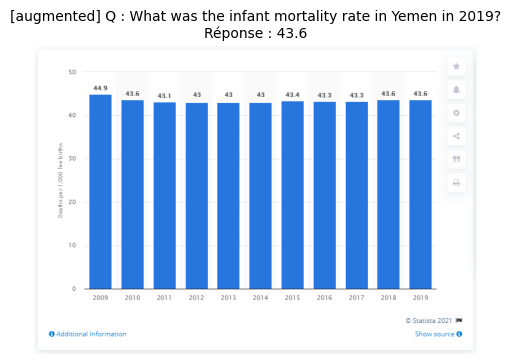

Table associée :


,Characteristic,"Deaths per 1,000 live births"
0,2019,43.6
1,2018,43.6
2,2017,43.3
3,2016,43.3
4,2015,43.4
5,2014,43.0
6,2013,43.0
7,2012,43.0


--------------------------------------------------------------------------------


In [17]:
def show_example(split="train", n=5, seed=1):
    sub = qa[qa.split == split].sample(n, random_state=seed)
    for _, r in sub.iterrows():
        png = os.path.join(PNG_DIR[split], r["imgname"])
        tab = read_table(table_path(split, r["imgname"]))
        fig, ax = plt.subplots(figsize=(7, 4)); ax.grid(False); ax.axis("off")
        ax.imshow(Image.open(png))
        ax.set_title(f"[{r['source']}] Q : {r['query']}\nRéponse : {r['label']}", fontsize=10)
        plt.show()
        print("Table associée :")
        display(tab.head(8) if tab is not None else "— table introuvable —")
        print("-" * 80)

show_example("train", n=5)

In [18]:
# Contrôle automatique : la réponse apparaît-elle dans la table ? (réponses de lecture directe)
def answer_in_table(split, imgname, label):
    t = read_table(table_path(split, imgname))
    if t is None: return np.nan
    flat = " ".join(map(str, t.values.flatten())).lower() + " " + " ".join(map(str, t.columns)).lower()
    return str(label).lower().strip() in flat

chk = qa[(qa.split == "train") & (qa.source == "human")].sample(500, random_state=0).copy()
chk["in_table"] = [answer_in_table("train", i, l) for i, l in zip(chk.imgname, chk.label)]
print("Réponse retrouvée telle quelle dans la table :", round(chk["in_table"].mean() * 100, 1), "%")
print("(les réponses calculées — sommes, différences — ne sont pas dans la table, c'est normal)")

Réponse retrouvée telle quelle dans la table : 53.8 %
(les réponses calculées — sommes, différences — ne sont pas dans la table, c'est normal)


## 8. Synthèse (à compléter avec tes chiffres)

| Point | Observation |
|---|---|
| Taille | … questions / … images par split |
| Origine des questions | humaines vs générées : … |
| Doublons / fuites train-test | … |
| Dimensions d'images | médiane … × … px, ratio … |
| Tables | médiane … lignes × … colonnes |
| Types de questions | … |
| Limites | graphiques propres (rendus), anglais, 4 sources, peu de bruit réel |

**Implications pour le pipeline** : …